# exp5_gamma_robustness — does the fairness reversal survive different γ?

R2's robustness question: the manuscript's fairness reversal (empathic
condition D more *unequal*, not less, than non-empathic condition A) was
observed at a single discount factor, γ = 0.99. `exp5` re-runs the A/D
contrast at γ ∈ {0.8, 0.9, 0.999}, keeping every other setting identical to
`exp1` (`see_resource=True`, `see_own_meals=True`).

**Design.** `main_gt_ais.py`'s `exp5_gamma_robustness` defines 12 conditions:
the 2×2 (A, B, C, D) at each γ, needed for the γ × ρ × α ANOVA of §5 bis. The
γ = 0.99 point is **not** re-run here: it is already covered by `exp1`'s four
conditions (they use the module's default `gamma=None`, which falls back to
`PARAMS_DQN["gamma"] = 0.99`). This notebook treats them as the γ = 0.99 **anchor**, loaded from `exp1_resource_obs`, so the trend
below spans all four γ values the tracker asks about without re-running
anything.

**Why γ = 0.8 is the interesting edge, not just another point on a grid.**
The RL discount factor sets an *effective planning horizon*
`H(γ) = 1/(1−γ)`. The personal-satisfaction / emotion signal, on the other
hand, is computed from a **fixed W = `memory_size` = 10-step sliding window**
of an agent's own meal history (`Agent.__init__`,
`agent_policies_gt_ais.py`) — a backward-looking boxcar average, entirely
independent of γ. At γ = 0.999 and γ = 0.99, `H(γ)` (1000 and 100 steps) is
far larger than W = 10: the agent's discounted return comfortably integrates
the *entire* window's worth of consequences of any one action, many times
over. At **γ = 0.8, `H(γ) = 5` steps — *below* the 10-step window** the
emotion signal is computed over. If the empathic effect on fairness turned
out to depend on agents being artificially far-sighted (able to "see" the
whole window ahead), it should weaken or disappear here.

It does not have to disappear completely, though, and the reason is
quantifiable rather than a matter of intuition. A single meal at time *t*
keeps contributing to personal reward for as long as it stays inside the
W-step window (uniform weight 1/W each step, `β`-boosted at *k*=0 for being
the "last meal"). Discounting that boxcar contribution geometrically gives
the **fraction of a meal's total window-credit** an agent with discount γ
actually integrates into its return:

```
credit_fraction(γ) = β + (1 − β) / W · (1 − γ^W) / (1 − γ)
```

which the cell below evaluates for β = 0.5, W = 10 at the four γ values in
play here. Even at γ = 0.8 the captured fraction is a majority, not a sliver
— H(γ) < W degrades the credit assigned to the *tail* of the window, it does
not erase it. More importantly, this only bounds the **personal** channel:
the *empathic* term an agent receives (`α · mean(others' emotions)`) is
computed from other agents' state and delivered as an **immediate** part of
`r_t` every step — it requires no foresight at all, regardless of γ (see the
earlier discussion in this project on this exact point). So γ = 0.8 is a
genuine stress test of the *personal* half of the reward trade-off, without
being an unfair test of the *empathic* mechanism itself.

**Two metrics, per γ, per condition (A vs. D):**
- **Depletion step** (`total_steps`) — sustainability.
- **Gini coefficient of meals** (`gini_meals`) — fairness, the reversal
  under test.

**This notebook is written to work with partial data.** As of this run,
only some of the 12 planned conditions (plus the γ = 0.99 anchor) have been
executed — see the inventory in §2, which is computed from whatever is on
disk rather than assumed. Sections that need a γ this machine has not
finished yet report that plainly instead of failing. As elsewhere, the final
analysis uses the **greedy evaluation episodes only** (`phase='eval'`,
ε = 0, no learning).

## 1. Setup

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

EXPERIMENT = "exp5_gamma_robustness"
RESULTS_DIR = Path("..") / "csv_results" / EXPERIMENT
ANCHOR_EXPERIMENT = "exp1_resource_obs"
ANCHOR_DIR = Path("..") / "csv_results" / ANCHOR_EXPERIMENT
ANCHOR_CONDITIONS = ["A_res_blind_non_empathic", "B_res_blind_reward_empathic",
                     "C_res_sees_ignores", "D_res_full_empathy"]  # gamma=0.99 default

LAST_N_EVAL = 10
ALPHA_LEVEL = 0.05
TARGET_SEEDS = 20

print(f"experiment : {EXPERIMENT}  (data: {RESULTS_DIR.resolve()})")
print(f"anchor     : gamma=0.99 pair from {ANCHOR_EXPERIMENT} (data: {ANCHOR_DIR.resolve()})")

experiment : exp5_gamma_robustness  (data: C:\Users\evann\OneDrive\Documents\1.neuro\ISIR\02_GT_AIS\csv_results\exp5_gamma_robustness)
anchor     : gamma=0.99 pair from exp1_resource_obs (data: C:\Users\evann\OneDrive\Documents\1.neuro\ISIR\02_GT_AIS\csv_results\exp1_resource_obs)


In [2]:
# chart chrome: recessive grid and axes, text in neutral ink, series colour
# reserved for the marks themselves. Lighter than exp1/exp3's palette block
# since this notebook has at most one figure.
SURFACE = "#fcfcfb"
INK = {"primary": "#0b0b0b", "secondary": "#52514e", "muted": "#898781",
       "grid": "#e1e0d9", "baseline": "#c3c2b7"}
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10,
    "axes.edgecolor": INK["baseline"], "axes.linewidth": 1.0,
    "axes.labelcolor": INK["secondary"], "axes.labelsize": 10,
    "axes.titlecolor": INK["primary"], "axes.titlesize": 11,
    "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
    "grid.color": INK["grid"], "grid.linewidth": 0.8,
    "xtick.color": INK["muted"], "ytick.color": INK["muted"],
    "xtick.labelcolor": INK["secondary"], "ytick.labelcolor": INK["secondary"],
    "text.color": INK["primary"], "legend.frameon": False, "legend.fontsize": 9,
})

METRIC_LABEL = {
    "depletion_step": "Depletion step (steps before the pool empties)",
    "gini_meals": "Gini coefficient of meals",
    "total_meals": "Total meals consumed per episode",
}

METRICS = ["depletion_step", "gini_meals"]

## 2. Credit-capture fraction vs. γ (pure computation, no data needed)

The formula from §0, evaluated at the γ values this experiment covers plus
the γ = 0.99 anchor. This table does not depend on any run having finished —
it is the quantitative backing for why γ = 0.8 is informative rather than
simply "too myopic to mean anything".

In [3]:
W, BETA = 10, 0.5   # memory_size and BETA in main_gt_ais.py / agent_policies_gt_ais.py

def credit_fraction(gamma, w=W, beta=BETA):
    return beta + (1 - beta) / w * (1 - gamma ** w) / (1 - gamma)

credit = pd.DataFrame({"gamma": [0.8, 0.9, 0.99, 0.999]})
credit["H_gamma_steps"] = 1 / (1 - credit["gamma"])
credit["credit_fraction_of_one_meal"] = credit["gamma"].apply(credit_fraction)
display(credit.style.format({"H_gamma_steps": "{:.0f}", "credit_fraction_of_one_meal": "{:.1%}"}))

,gamma,H_gamma_steps,credit_fraction_of_one_meal
0,0.800000,5,72.3%
1,0.900000,10,82.6%
2,0.990000,100,97.8%
3,0.999000,1000,99.8%


## 3. Load the runs

`exp5`'s own folder, plus the γ = 0.99 anchor pair from `exp1`. `gamma` is
already a column of the summary CSVs (`main_gt_ais.py`,
`write_summary_csv`), including for the anchor conditions (where it reports
the resolved default, 0.99) — no label parsing needed.

In [4]:
def load_summaries(results_dir: Path) -> pd.DataFrame:
    """Concatenate every *_episode_summary.csv of one experiment folder.

    The runner writes all condition parameters as columns (main_gt_ais.py,
    summary_header()), so no filename parsing is needed.
    """
    files = sorted(results_dir.glob("*_episode_summary.csv"))
    if not files:
        raise FileNotFoundError(f"no *_episode_summary.csv under {results_dir.resolve()}")
    frames = []
    for path in files:
        one = pd.read_csv(path)
        one["source_file"] = path.name
        frames.append(one)
    return pd.concat(frames, ignore_index=True)


def add_derived(frame: pd.DataFrame) -> pd.DataFrame:
    frame = frame.copy()
    frame["depletion_step"] = frame["total_steps"]
    frame["censored"] = (frame["total_steps"] >= frame["max_steps"]) & (frame["resource_remaining"] > 0)
    meal_cols = [c for c in frame.columns if re.fullmatch(r"meals_\d+", c)]
    frame["total_meals"] = frame[meal_cols].sum(axis=1)
    frame["family"] = frame["condition"].str[0]  # 'A' to 'D'
    return frame


df = add_derived(load_summaries(RESULTS_DIR))
ev = df[df["phase"] == "eval"].copy()

HAVE_ANCHOR = ANCHOR_DIR.exists() and any(ANCHOR_DIR.glob("*_episode_summary.csv"))
if HAVE_ANCHOR:
    anchor_full = add_derived(load_summaries(ANCHOR_DIR))
    anchor = anchor_full[anchor_full["condition"].isin(ANCHOR_CONDITIONS)
                         & anchor_full["reward_scheme"].isin(df["reward_scheme"].unique())].copy()
    ev_anchor = anchor[anchor["phase"] == "eval"].copy()
    if ev_anchor.empty:
        print(f"NOTE: {ANCHOR_EXPERIMENT} present but no rows for {ANCHOR_CONDITIONS} -- "
              f"the gamma=0.99 anchor will be missing below.")
        HAVE_ANCHOR = False
else:
    print(f"NOTE: {ANCHOR_EXPERIMENT} not found -- the gamma=0.99 anchor will be missing, "
          f"the trend below will only cover exp5's own gamma values.")

ev_all = pd.concat([ev, ev_anchor], ignore_index=True) if HAVE_ANCHOR else ev.copy()

inventory = (ev_all.groupby(["family", "gamma"], observed=True)
                   .agg(condition=("condition", "first"), seeds=("seed", "nunique"),
                        eval_episodes=("episode", "size"))
                   .reset_index()
                   .sort_values(["family", "gamma"]))
inventory["seeds_missing_vs_target"] = TARGET_SEEDS - inventory["seeds"]
display(inventory)

pivot_seeds = ev_all.groupby(["gamma", "family"], observed=True)["seed"].nunique().unstack("family")
print("\nseeds available per (gamma, family) -- NaN means that cell has not been run yet:")
display(pivot_seeds)

PLANNED_GAMMAS = sorted(set([0.8, 0.9, 0.99, 0.999]))
missing = [g for g in PLANNED_GAMMAS
          if g not in pivot_seeds.index or pivot_seeds.loc[g].isna().any()
          or (pivot_seeds.loc[g] == 0).any()]
if missing:
    print(f"\nNOTE per EXPERIMENT_TRACKER.md: gamma value(s) {missing} do not yet have both "
          f"A and D populated. Sections below only analyse gamma values with a complete pair.")

,family,gamma,condition,seeds,eval_episodes,seeds_missing_vs_target
0,A,0.90,A_res_gamma090,6,229,14
1,A,0.99,A_res_blind_non_empathic,11,550,9
2,D,0.99,D_res_full_empathy,11,550,9



seeds available per (gamma, family) -- NaN means that cell has not been run yet:


family,A,D
gamma,,
0.90,6.0,NaN
0.99,11.0,11.0



NOTE per EXPERIMENT_TRACKER.md: gamma value(s) [0.8, 0.9, 0.999] do not yet have both A and D populated. Sections below only analyse gamma values with a complete pair.


## 4. Data integrity and end-of-training aggregation

Same checks as elsewhere (duplicated episodes, censoring), then one row per
(family, gamma, seed): mean over the last `LAST_N_EVAL` greedy evaluation
episodes.

In [5]:
dupes = int(ev_all.duplicated(subset=["condition", "seed", "phase", "episode"]).sum())
print(f"duplicate (condition, seed, phase, episode) rows : {dupes}")
assert dupes == 0, "duplicated episode rows -- check for a re-run written twice"

censoring = (ev_all.groupby(["family", "gamma"], observed=True)
                   .agg(eval_episodes=("censored", "size"), censored_rate=("censored", "mean"))
                   .reset_index().sort_values(["family", "gamma"]))
display(censoring.style.format({"censored_rate": "{:.1%}"}))


def end_of_training(eval_df, group_keys, last_n=LAST_N_EVAL):
    tail = (eval_df.sort_values("episode")
                   .groupby(group_keys + ["seed"], observed=True)
                   .tail(last_n))
    return (tail.groupby(group_keys + ["seed"], observed=True)
                .agg(depletion_step=("depletion_step", "mean"),
                     gini_meals=("gini_meals", "mean"),
                     total_meals=("total_meals", "mean"),
                     n_eval=("episode", "size"))
                .reset_index())


seed_df = end_of_training(ev_all, ["condition", "family", "gamma"])
summary = (seed_df.groupby(["family", "gamma"], observed=True)[METRICS]
                  .agg(["mean", "std", "count"]).sort_index())
display(summary.style.format("{:.3f}"))

duplicate (condition, seed, phase, episode) rows : 0


,family,gamma,eval_episodes,censored_rate
0,A,0.900000,229,14.8%
1,A,0.990000,550,17.8%
2,D,0.990000,550,33.6%


## 5. The A vs. D contrast, per γ

For every γ value where **both** A and D have at least 2 seeds, Welch's
t-test, Mann-Whitney U and Hedges' g on the D − A difference — the same
trio as the planned contrast in `exp1`'s §10, repeated once per available γ.
This is the direct test of whether the fairness reversal (`gini_meals`
higher under D) and the sustainability gain (`depletion_step` higher under
D) persist as γ shrinks.

In [6]:
def hedges_g(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    na, nb = len(a), len(b)
    pooled = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
    d = (a.mean() - b.mean()) / pooled
    g = d * (1 - 3 / (4 * (na + nb) - 9))
    se = np.sqrt((na + nb) / (na * nb) + g ** 2 / (2 * (na + nb - 2)))
    return float(g), float(g - 1.96 * se), float(g + 1.96 * se)


def stars(p):
    return "***" if p < .001 else "**" if p < .01 else "*" if p < .05 else "ns"


contrast_rows = []
for gamma in sorted(seed_df["gamma"].unique()):
    a = seed_df.loc[(seed_df["gamma"] == gamma) & (seed_df["family"] == "A"), :]
    d = seed_df.loc[(seed_df["gamma"] == gamma) & (seed_df["family"] == "D"), :]
    if len(a) < 2 or len(d) < 2:
        print(f"gamma={gamma}: incomplete (n_A={len(a)}, n_D={len(d)}) -- skipped, "
              f"see EXPERIMENT_TRACKER.md")
        continue
    print("=" * 78)
    print(f"gamma = {gamma}   (n_A={len(a)}, n_D={len(d)}, H(gamma)={1/(1-gamma):.0f} steps)")
    print("=" * 78)
    for metric in METRICS:
        av, dv = a[metric].to_numpy(), d[metric].to_numpy()
        welch = stats.ttest_ind(dv, av, equal_var=False)
        u, p_u = stats.mannwhitneyu(dv, av, alternative="two-sided")
        g, lo, hi = hedges_g(dv, av)
        print(f"  {METRIC_LABEL[metric]}")
        print(f"    A: {av.mean():8.3f}   D: {dv.mean():8.3f}   D-A: {dv.mean()-av.mean():+8.3f}")
        print(f"    Welch t({welch.df:.1f})={welch.statistic:.3f}, p={welch.pvalue:.4f} "
              f"{stars(welch.pvalue)}   |   MWU p={p_u:.4f} {stars(p_u)}   |   "
              f"Hedges g={g:+.2f} [{lo:+.2f}, {hi:+.2f}]")
        contrast_rows.append({"gamma": gamma, "metric": metric, "diff_D_minus_A": dv.mean() - av.mean(),
                              "p_welch": welch.pvalue, "hedges_g": g})

contrasts = pd.DataFrame(contrast_rows)

gamma=0.9: incomplete (n_A=6, n_D=0) -- skipped, see EXPERIMENT_TRACKER.md
gamma = 0.99   (n_A=11, n_D=11, H(gamma)=100 steps)
  Depletion step (steps before the pool empties)
    A:  619.900   D:  766.391   D-A: +146.491
    Welch t(18.2)=7.179, p=0.0000 ***   |   MWU p=0.0001 ***   |   Hedges g=+2.94 [+1.71, +4.18]
  Gini coefficient of meals
    A:    0.040   D:    0.184   D-A:   +0.144
    Welch t(10.3)=11.692, p=0.0000 ***   |   MWU p=0.0001 ***   |   Hedges g=+4.80 [+3.09, +6.50]


## 5 bis. Does γ moderate the two components?

Three-way ANOVA γ × ρ × $w_e$ (method, *Shared discount*). γ is carried over to Axes 2
and 3 under the same rule as the resource: an interaction with ρ, $w_e$ or both at
$p < .05$ and $\eta_p^2 \ge .06$.

In [ ]:
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm

full = end_of_training(ev_all, ["condition", "gamma", "see_emotions", "alpha"])
counts = full.groupby(["gamma", "see_emotions", "alpha"], observed=True).seed.nunique()
if len(counts) < 2 * 2 * full.gamma.nunique() or full.gamma.nunique() < 2 or counts.min() < 2:
    print("the gamma x rho x alpha design is not complete yet:")
    display(counts.unstack("gamma"))
else:
    for metric in METRICS:
        table = anova_lm(ols(f"{metric} ~ C(gamma) * C(see_emotions) * C(alpha)", data=full).fit(), typ=2)
        table["partial_eta_sq"] = table.sum_sq / (table.sum_sq + table.loc["Residual", "sum_sq"])
        table.loc["Residual", "partial_eta_sq"] = np.nan
        print(METRIC_LABEL[metric])
        display(table.round(4))
        moderating = [t for t in table.index if "gamma" in t and ":" in t
                      and table.loc[t, "PR(>F)"] < ALPHA_LEVEL and table.loc[t, "partial_eta_sq"] >= 0.06]
        print("-> carried over to Axes 2 and 3" if moderating else
              "-> no interaction meeting the rule: gamma fixed at 0.99", moderating)

## 6. Figure: the D − A gap across γ

Only plotted for γ values with a complete pair (§5); still useful even with
a single point, as a placeholder that will fill in as more of `exp5`
finishes. One panel per metric, so the figure stays a single 1-row grid
regardless of how many γ values are available yet.

findfont: Failed to find font weight semibold, now using 700.


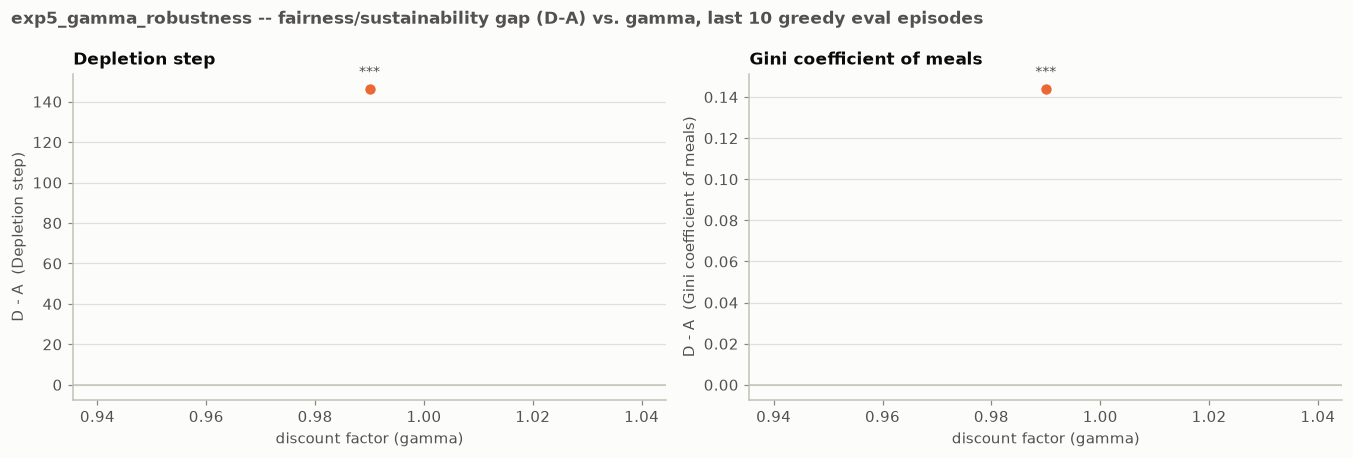

In [7]:
if contrasts.empty:
    print("No gamma value has a complete A/D pair yet -- nothing to plot. Re-run this cell "
          "once exp5_gamma_robustness has more runs (see EXPERIMENT_TRACKER.md).")
else:
    fig, axes = plt.subplots(1, len(METRICS), figsize=(6.2 * len(METRICS), 4.2))
    axes = np.atleast_1d(axes)
    for ax, metric in zip(axes, METRICS):
        sub = contrasts[contrasts["metric"] == metric].sort_values("gamma")
        ax.axhline(0, color=INK["baseline"], lw=1.0, zorder=1)
        ax.plot(sub["gamma"], sub["diff_D_minus_A"], marker="o", ms=8, color=CAT[1],
               mec=SURFACE, mew=1.2, lw=1.8, zorder=3)
        for _, row in sub.iterrows():
            ax.annotate(stars(row["p_welch"]), (row["gamma"], row["diff_D_minus_A"]),
                       textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9,
                       color=INK["secondary"])
        short_label = METRIC_LABEL[metric].split(" (")[0]
        ax.set_xlabel("discount factor (gamma)")
        ax.set_ylabel(f"D - A  ({short_label})")
        ax.set_title(short_label)
    fig.suptitle("exp5_gamma_robustness -- fairness/sustainability gap (D-A) vs. gamma, "
                 f"last {LAST_N_EVAL} greedy eval episodes", x=0.012, ha="left", fontsize=11,
                 fontweight="semibold", color=INK["secondary"])
    fig.tight_layout()
    plt.show()

## 7. Read-out

Auto-generated from whatever γ cells are complete, so it stays correct as
more of `exp5` finishes.

In [8]:
print("=" * 78)
print("exp5_gamma_robustness -- current status")
print("=" * 78)
done_gammas = sorted(contrasts["gamma"].unique()) if not contrasts.empty else []
print(f"complete A/D pairs : {done_gammas if done_gammas else 'none yet'}")
print(f"still pending      : {[g for g in PLANNED_GAMMAS if g not in done_gammas]}")

if not contrasts.empty:
    for metric in METRICS:
        sub = contrasts[contrasts["metric"] == metric].sort_values("gamma")
        signs = set(np.sign(sub["diff_D_minus_A"]))
        consistent = len(signs) == 1
        print(f"\n  {METRIC_LABEL[metric]}")
        for _, row in sub.iterrows():
            print(f"    gamma={row['gamma']:<6} D-A={row['diff_D_minus_A']:+.3f}  "
                  f"p={row['p_welch']:.4f} {stars(row['p_welch'])}")
        print(f"    sign {'consistent' if consistent else 'NOT consistent'} across the "
              f"available gamma values")

print("\n" + "-" * 78)
print("CAVEATS")
print("  - see the inventory in SS3 for exact seed counts per (family, gamma); most cells "
      "are below TARGET_SEEDS while this experiment is still running.")
print("  - gamma=0.99 is borrowed from exp1_resource_obs (conditions "
      "A to D), not re-run inside exp5 itself.")
print("  - SS0/SS2 bound the *personal* credit-assignment channel only; the empathic term is "
      "delivered as an immediate reward every step and is not, by that argument, expected "
      "to need a long gamma to function.")

exp5_gamma_robustness -- current status
complete A/D pairs : [np.float64(0.99)]
still pending      : [0.8, 0.9, 0.999]

  Depletion step (steps before the pool empties)
    gamma=0.99   D-A=+146.491  p=0.0000 ***
    sign consistent across the available gamma values

  Gini coefficient of meals
    gamma=0.99   D-A=+0.144  p=0.0000 ***
    sign consistent across the available gamma values

------------------------------------------------------------------------------
CAVEATS
  - see the inventory in SS3 for exact seed counts per (family, gamma); most cells are below TARGET_SEEDS while this experiment is still running.
  - gamma=0.99 is borrowed from exp1_resource_obs (A_res_blind_non_empathic / D_res_full_empathy), not re-run inside exp5 itself.
  - SS0/SS2 bound the *personal* credit-assignment channel only; the empathic term is delivered as an immediate reward every step and is not, by that argument, expected to need a long gamma to function.
